# Testing portfolio sensitivity to covariance cleaning

This Julia notebook follows the same experiment, equations, sample sizes, parameters, and decision rules as its Python counterpart. Random experiments use the displayed integer seeds with Julia’s `Xoshiro` generator, so their realized samples differ from NumPy. Public observations use the same stated data sources. Figures use the requested dark theme, and Julia outputs are saved under `outputs/julia`. Gaussian simulations use Cholesky factors. NERCOME uses saved Xoshiro row permutations with the same split fraction and split count. Saved draws, covariances, and portfolio weights allow the calculations to be repeated across languages.

The global minimum-variance portfolio gives the fully invested weights with the smallest variance under the supplied covariance matrix:

$$
w_{\mathrm{GMV}}(\Sigma)
=\frac{\Sigma^{-1}\mathbf 1}{\mathbf 1^{\mathsf T}\Sigma^{-1}\mathbf 1},
\qquad
\mathbf 1^{\mathsf T}w_{\mathrm{GMV}}=1.
$$

Here, $\Sigma$ is an invertible covariance matrix; $\Sigma^{-1}$ is its inverse; $\mathbf 1$ is a vector of ones. $w_{\mathrm{GMV}}$ is the weight vector; $\mathsf T$ denotes transpose; the denominator rescales the weights to sum to one.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("10_covariance_denoising");
using CSV, Printf
using RiskLabAI.Data: corr_to_cov,cov_to_corr,denoise_cov,denoised_corr,denoised_corr2,find_max_eval,fit_kde,score_samples,marcenko_pastur_pdf,nercome_denoised_covariance,optimal_portfolio,optimal_portfolio_denoised,pca
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
public_lines = readlines(data_path)
header_row = findfirst(startswith(",Agric"),public_lines)
end_row = findnext(line->isempty(strip(line)),public_lines,header_row+1)
raw = CSV.read(IOBuffer(join(public_lines[header_row:end_row-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
all_returns = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_returns.!=-99.99).&(all_returns.!=-999.0);dims=2))
industry_dates = all_dates[valid]
industry_names = names(raw)[2:end]
industry_returns = all_returns[valid,:]./100
violet = "#C084FC"

function matrix_frame(matrix;metadata...)
    prefix = DataFrame([name=>fill(value,size(matrix,1)) for (name,value) in pairs(metadata)]...)
    return hcat(prefix,DataFrame(row=collect(1:size(matrix,1))),DataFrame(matrix,["x"*string(index) for index in axes(matrix,2)]))
end

function covariance_fit(covariance,q,bandwidth)
    correlation = cov_to_corr(covariance)
    values,vectors = pca(correlation)
    cutoff,variance = find_max_eval(values,q,bandwidth)
    diagnostic = RiskLabAI.Data._mp_bounded_local_min(v->RiskLabAI.Data._mp_pdf_fit_error(v,q,values,bandwidth);derivative=v->RiskLabAI.Data._mp_pdf_fit_gradient(v,q,values,bandwidth))
    @assert variance==(diagnostic.converged ? diagnostic.variance : 1.)
    factors = count(>(cutoff),values)
    return (correlation=correlation,values=values,vectors=vectors,cutoff=cutoff,variance=variance,factors=factors,converged=diagnostic.converged,latent_variance=diagnostic.variance,objective=diagnostic.objective,iterations=diagnostic.iterations)
end

function add_fliers!(figure,groups)
    for (index,values) in enumerate(groups)
        lower,upper = quantile(values,[.25,.75])
        spread = upper-lower
        outside = values[(values.<lower-1.5spread).|(values.>upper+1.5spread)]
        scatter!(figure,fill(index,length(outside)),outside;color=palette.text,markersize=3,markerstrokewidth=0,label=false)
    end
    return figure
end
function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end


box_summary! (generic function with 1 method)

## Why Small Eigenvalues Matter

The bound shows how a small covariance change can create a much larger change in its inverse when the condition number is large:

$$
\frac{\lVert(\Sigma+\Delta)^{-1}-\Sigma^{-1}\rVert_2}{\lVert\Sigma^{-1}\rVert_2}
\leq
\frac{\kappa_2(\Sigma)\,\lVert\Delta\rVert_2/\lVert\Sigma\rVert_2}
{1-\kappa_2(\Sigma)\,\lVert\Delta\rVert_2/\lVert\Sigma\rVert_2},
\qquad
\kappa_2(\Sigma)\frac{\lVert\Delta\rVert_2}{\lVert\Sigma\rVert_2}<1.
$$

Here, $\Sigma$ is the original positive-definite covariance; $\Delta$ is a perturbation; $\kappa_2(\Sigma)$ is its spectral condition number. $\lVert\cdot\rVert_2$ is the spectral norm; $(\Sigma+\Delta)^{-1}$ and $\Sigma^{-1}$ are the perturbed and original inverses. The final inequality is the condition required for the displayed finite upper bound.

In [2]:
base_window = industry_returns[1:125,:]
base_covariance = cov(base_window)
base_correlation = cov_to_corr(base_covariance)
perturbation_levels = 10.0.^range(-8,-2;length=13)
direction_primitive = randn(Xoshiro(9027),size(base_covariance))
direction = (direction_primitive+transpose(direction_primitive))/2
direction ./= opnorm(direction)
perturbation_rows = NamedTuple[]
for relative_size in perturbation_levels
    perturbation = direction*relative_size*opnorm(base_covariance)
    if minimum(eigvals(Symmetric(base_covariance+perturbation)))<=0
        perturbation = Matrix{Float64}(I,49,49)*relative_size*opnorm(base_covariance)
    end
    relative_inverse_change = opnorm(inv(base_covariance+perturbation)-inv(base_covariance))/opnorm(inv(base_covariance))
    relative_change = opnorm(perturbation)/opnorm(base_covariance)
    condition_product = cond(base_covariance)*relative_change
    upper_bound = condition_product<1 ? condition_product/(1-condition_product) : NaN
    push!(perturbation_rows,(relative=relative_change,inverse=relative_inverse_change,product=condition_product,bound=upper_bound))
end
inverse_sensitivity = DataFrame(perturbation_rows)
rename!(inverse_sensitivity,["Relative covariance change","Relative inverse change","Condition product","Finite upper bound"])
inverse_sensitivity_display = inverse_sensitivity[1:2:13,:]
save_table(inverse_sensitivity_display,paths,"inverse_sensitivity";caption="Inverse sensitivity for controlled perturbations of a public sample covariance.",label="tab:chapter9-inverse-sensitivity")
save_data(inverse_sensitivity,paths,"inverse_sensitivity_full")
save_data(matrix_frame(direction_primitive),paths,"perturbation_gaussian_draws");


Row,Relative covariance change,Relative inverse change,Condition product,Finite upper bound
,Float64,Float64,Float64,Float64
1,1.0e-8,1.84213e-6,1.17807e-5,1.17808e-5
2,1.0e-7,1.84207e-5,0.000117807,0.000117821
3,1.0e-6,0.000184144,0.00117807,0.00117946
4,1.0e-5,0.00183525,0.0117807,0.0119211
5,0.0001,0.0177543,0.117807,0.133539
6,0.001,0.241745,1.17807,NaN
7,0.01,0.921757,11.7807,NaN


## Known-Truth Weight Recovery

The first quantity measures weight error against the known optimal portfolio, and the second measures variance under the known covariance:

$$
\operatorname{RMSE}_w(m)
=\sqrt{\frac{1}{N}\sum_{i=1}^{N}\left(\widehat w_{i,m}-w_{i,0}\right)^2},
\qquad
V_m=\widehat w_m^{\mathsf T}\Sigma_0\widehat w_m.
$$

Here, $N$ is the number of portfolios; $i$ indexes a portfolio; $m$ names a covariance method. $\widehat w_{i,m}$ is estimated weight $i$; $w_{i,0}$ is its known-truth value; $\operatorname{RMSE}_w(m)$ is root mean squared weight error. $\widehat w_m$ is the full estimated weight vector; $\Sigma_0$ is the known covariance; $V_m$ is realized true variance; $\mathsf T$ denotes transpose.

Row,Method,Mean weight root mean squared error,Median weight root mean squared error,Mean weight absolute error,Mean realized true variance,Mean gross exposure
,String,Float64,Float64,Float64,Float64,Float64
1,Sample covariance,0.0464169,0.0461117,1.78137,3.1375e-5,2.17634
2,Cleaned covariance,0.0230317,0.0231699,0.875431,2.10305e-5,1.36381
3,One-step cleaned covariance,0.0230317,0.0231699,0.875431,2.10305e-5,1.36381


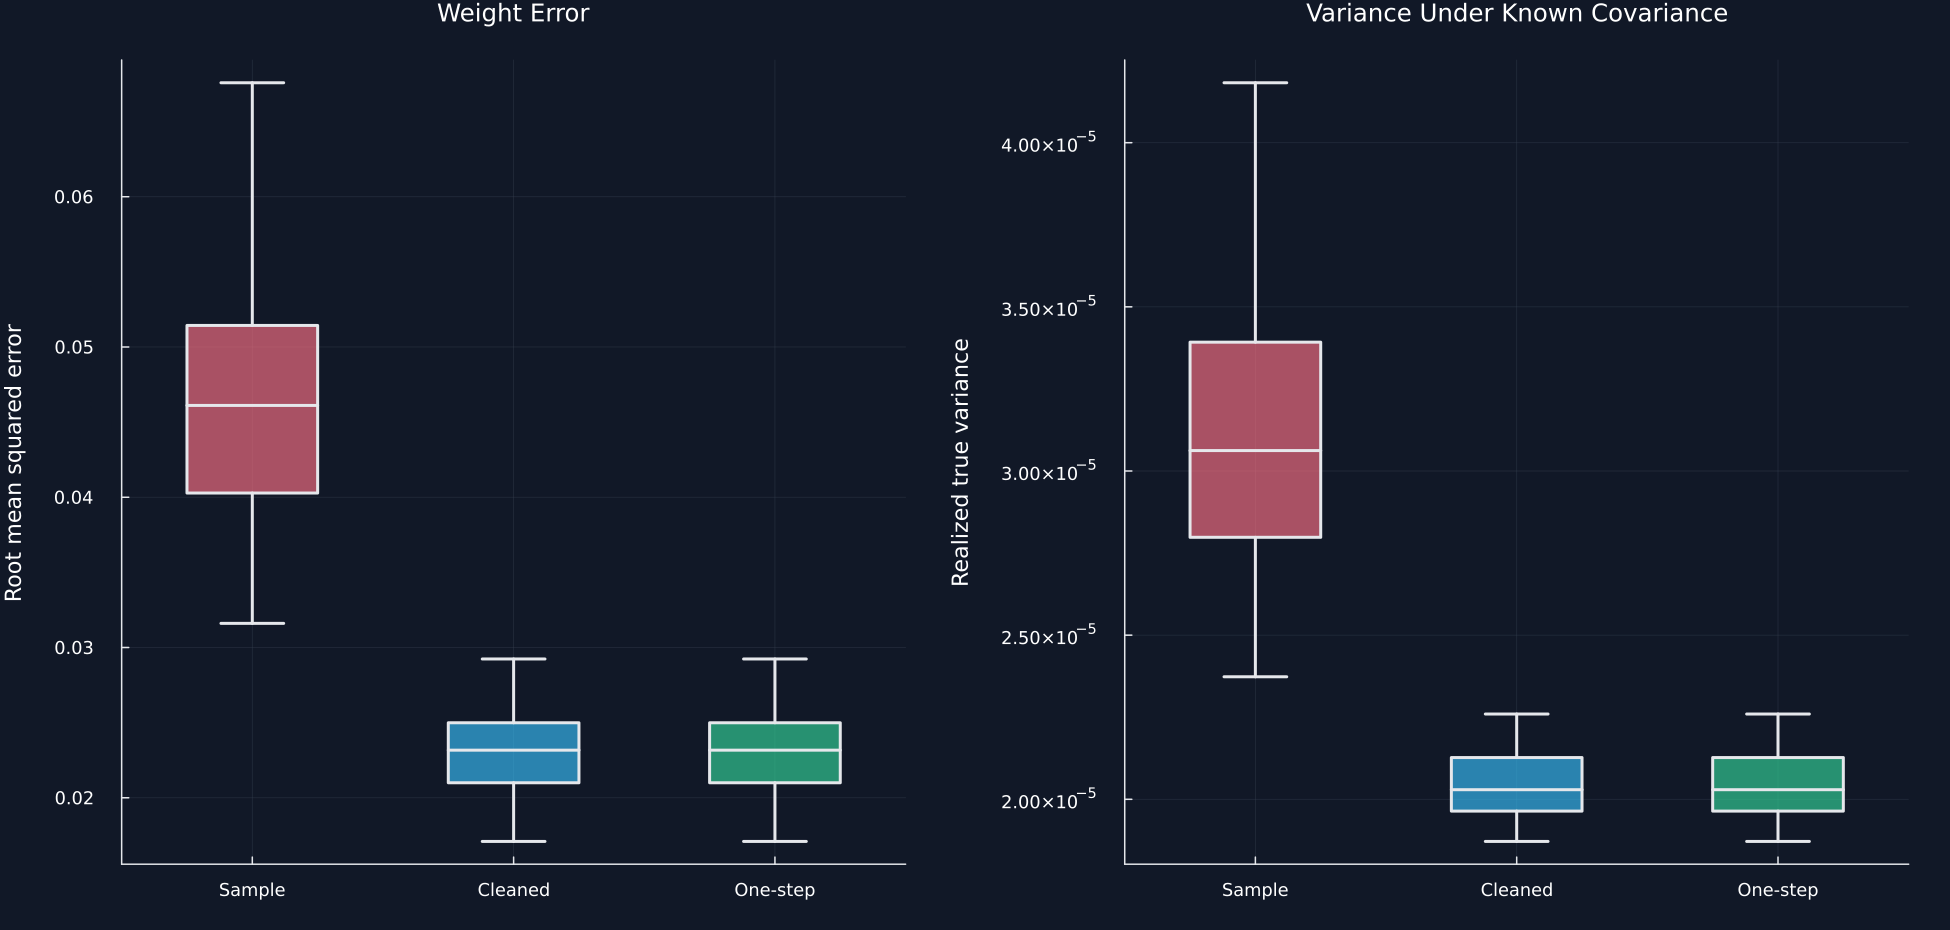

In [3]:
weight_block_size,weight_block_count,weight_correlation = 7,7,.5
weight_observations,weight_repetitions = 100,100
weight_block = (1-weight_correlation)*Matrix{Float64}(I,7,7)+weight_correlation*ones(7,7)
weight_true_correlation = kron(Matrix{Float64}(I,7,7),weight_block)
weight_true_scale = vec(std(industry_returns;dims=1))
weight_true_covariance = corr_to_cov(weight_true_correlation,weight_true_scale)
weight_true_portfolio = optimal_portfolio(weight_true_covariance)
weight_cholesky = cholesky(Symmetric(weight_true_covariance)).L
weight_q_ratio = weight_observations/49
weight_rows,weight_fit_rows = NamedTuple[],NamedTuple[]
one_step_differences = Float64[]
weight_draws,weight_covariances,weight_vectors = DataFrame(),DataFrame(),DataFrame()
weight_methods = ["Sample covariance","Cleaned covariance","One-step cleaned covariance"]
for repetition in 0:weight_repetitions-1
    primitive = randn(Xoshiro(9300+repetition),weight_observations,49)
    simulated_returns = primitive*transpose(weight_cholesky)
    sample_estimate = cov(simulated_returns)
    cleaned_estimate = denoise_cov(sample_estimate,weight_q_ratio;bandwidth=.01)
    current = covariance_fit(sample_estimate,weight_q_ratio,.01)
    sample_weights = optimal_portfolio(sample_estimate)
    cleaned_weights = optimal_portfolio(cleaned_estimate)
    one_step_weights = optimal_portfolio_denoised(sample_estimate,weight_q_ratio;bandwidth=.01)
    push!(one_step_differences,maximum(abs.(cleaned_weights.-one_step_weights)))
    push!(weight_fit_rows,(repetition=repetition+1,cutoff=current.cutoff,variance=current.variance,factors=current.factors,converged=current.converged,latent_variance=current.latent_variance,objective=current.objective,iterations=current.iterations,one_step_difference=last(one_step_differences)))
    append!(weight_draws,matrix_frame(primitive;repetition=repetition+1,seed=9300+repetition);cols=:union)
    for (method,estimate) in [("Sample covariance",sample_estimate),("Cleaned covariance",cleaned_estimate)]
        append!(weight_covariances,matrix_frame(estimate;repetition=repetition+1,method);cols=:union)
    end
    for (method,weights) in zip(weight_methods,[sample_weights,cleaned_weights,one_step_weights])
        push!(weight_rows,(repetition=repetition+1,method=method,rmse=sqrt(mean((weights.-weight_true_portfolio).^2)),absolute=sum(abs.(weights.-weight_true_portfolio)),variance=dot(weights,weight_true_covariance*weights),gross=sum(abs,weights)))
        append!(weight_vectors,DataFrame(repetition=fill(repetition+1,49),method=fill(method,49),industry=1:49,weight=weights);cols=:union)
    end
end
weight_recovery_runs = DataFrame(weight_rows)
rename!(weight_recovery_runs,["Repetition","Method","Weight root mean squared error","Weight absolute error","Realized true variance","Gross exposure"])
weight_summary_rows = NamedTuple[]
for method in weight_methods
    group = weight_recovery_runs[weight_recovery_runs.Method.==method,:]
    push!(weight_summary_rows,(method=method,rmse_mean=mean(group[!,"Weight root mean squared error"]),rmse_median=median(group[!,"Weight root mean squared error"]),absolute=mean(group[!,"Weight absolute error"]),variance=mean(group[!,"Realized true variance"]),gross=mean(group[!,"Gross exposure"])))
end
weight_recovery_summary = DataFrame(weight_summary_rows)
rename!(weight_recovery_summary,["Method","Mean weight root mean squared error","Median weight root mean squared error","Mean weight absolute error","Mean realized true variance","Mean gross exposure"])
save_table(weight_recovery_summary,paths,"weight_recovery_summary";caption="Known-truth portfolio weight and variance errors across one hundred repetitions.",label="tab:chapter9-weight-recovery")
save_data(weight_recovery_runs,paths,"weight_recovery_runs")
save_data(weight_draws,paths,"weight_gaussian_draws")
save_data(weight_covariances,paths,"weight_covariances")
save_data(weight_vectors,paths,"weight_vectors")
save_data(DataFrame(weight_fit_rows),paths,"weight_noise_fits")
save_data(matrix_frame(weight_true_covariance),paths,"weight_true_covariance")
save_data(DataFrame(industry=1:49,weight=weight_true_portfolio),paths,"weight_true_portfolio")
weight_method_colors = [palette.rose,palette.cyan,palette.green]
p1 = plot(;title="Weight Error",ylabel="Root mean squared error",xticks=(1:3,["Sample","Cleaned","One-step"]),xlims=(.5,3.5),legend=false)
p2 = plot(;title="Variance Under Known Covariance",ylabel="Realized true variance",xticks=(1:3,["Sample","Cleaned","One-step"]),xlims=(.5,3.5),legend=false)
box_summary!(p1,[weight_recovery_runs[weight_recovery_runs.Method.==method,"Weight root mean squared error"] for method in weight_methods],weight_method_colors)
box_summary!(p2,[weight_recovery_runs[weight_recovery_runs.Method.==method,"Realized true variance"] for method in weight_methods],weight_method_colors)
save_figure(plot(p1,p2;layout=(1,2),size=(1300,620)),paths,"known_truth_weight_recovery")


## Evaluating rolling portfolios out of sample

The first quantity is annualized volatility measured after weight selection, and the second records weight changes between evaluation windows:

$$
\widehat\sigma_{k,m}^{\mathrm{test}}
=\sqrt{252}\,\operatorname{sd}\!\left(R_k^{\mathrm{test}}w_{k,m}\right),
\qquad
\operatorname{turnover}_{k,m}
=\frac{1}{2}\lVert w_{k,m}-w_{k-1,m}\rVert_1.
$$

Here, $k$ labels a rolling window; $m$ labels a covariance method; $R_k^{\mathrm{test}}$ is its held-out return matrix. $w_{k,m}$ contains weights chosen from the preceding training window; $\operatorname{sd}$ is sample standard deviation; $252$ is trading days per year. $\lVert\cdot\rVert_1$ is the sum of absolute entries; turnover is one half of the total absolute weight change.

In [4]:
training_days,testing_days,step_days = 125,21,63
rolling_rows,rolling_fit_rows = NamedTuple[],NamedTuple[]
rolling_weights,rolling_covariances = DataFrame(),DataFrame()
previous_weights = Dict{String,Vector{Float64}}()
fold_number = 0
methods = ["Sample covariance","Constant residual","Targeted, alpha 0.5","Equal weight"]
for training_end in training_days:step_days:size(industry_returns,1)-testing_days
    training = industry_returns[training_end-training_days+1:training_end,:]
    testing = industry_returns[training_end+1:training_end+testing_days,:]
    covariance_sample = cov(training)
    q_fold = training_days/49
    covariance_constant = denoise_cov(covariance_sample,q_fold;bandwidth=.05)
    current = covariance_fit(covariance_sample,q_fold,.05)
    correlation_targeted = denoised_corr2(Diagonal(current.values),current.vectors,current.factors;alpha=.5)
    covariance_targeted = corr_to_cov(correlation_targeted,sqrt.(diag(covariance_sample)))
    method_weights = [optimal_portfolio(covariance_sample),optimal_portfolio(covariance_constant),optimal_portfolio(covariance_targeted),fill(1/49,49)]
    fold_number += 1
    push!(rolling_fit_rows,(fold=fold_number,training_end=training_end,cutoff=current.cutoff,variance=current.variance,factors=current.factors,converged=current.converged,latent_variance=current.latent_variance,objective=current.objective,iterations=current.iterations))
    for (method,estimate) in zip(methods[1:3],[covariance_sample,covariance_constant,covariance_targeted])
        append!(rolling_covariances,matrix_frame(estimate;fold=fold_number,method);cols=:union)
    end
    for (method,weights) in zip(methods,method_weights)
        held_out_returns = testing*weights
        turnover = haskey(previous_weights,method) ? .5sum(abs.(weights.-previous_weights[method])) : NaN
        push!(rolling_rows,(fold=fold_number,training_end=string(industry_dates[training_end]),test_start=string(industry_dates[training_end+1]),test_end=string(industry_dates[training_end+testing_days]),method=method,volatility=std(held_out_returns)*sqrt(252.),gross=sum(abs,weights),largest=maximum(abs,weights),concentration=sum(abs2,weights),turnover=turnover,sum=sum(weights),factors=current.factors))
        append!(rolling_weights,DataFrame(fold=fill(fold_number,49),method=fill(method,49),industry=1:49,weight=weights);cols=:union)
        previous_weights[method] = weights
    end
end
rolling_results = DataFrame(rolling_rows)
rename!(rolling_results,["Fold","Training end","Test start","Test end","Method","Annualized test volatility","Gross exposure","Largest absolute weight","Weight concentration","Turnover","Weight sum","Signal directions"])
sample_risk = rolling_results[rolling_results.Method.=="Sample covariance","Annualized test volatility"]
summary_rows,rolling_weight_rows,pairwise_rows = NamedTuple[],NamedTuple[],NamedTuple[]
for method in methods
    group = rolling_results[rolling_results.Method.==method,:]
    risk = group[!,"Annualized test volatility"]
    turnover = group.Turnover[isfinite.(group.Turnover)]
    push!(summary_rows,(method=method,mean=mean(risk),median=median(risk),minimum=minimum(risk),maximum=maximum(risk)))
    push!(rolling_weight_rows,(method=method,gross=median(group[!,"Gross exposure"]),largest=median(group[!,"Largest absolute weight"]),concentration=median(group[!,"Weight concentration"]),turnover=mean(turnover)))
    push!(pairwise_rows,(method=method,ratio=mean(risk./sample_risk),wins=count(risk.<sample_risk),folds=length(risk)))
end
rolling_portfolio_summary = DataFrame(summary_rows)
rename!(rolling_portfolio_summary,["Method","Mean annualized test volatility","Median annualized test volatility","Smallest annualized test volatility","Largest annualized test volatility"])
rolling_weight_summary = DataFrame(rolling_weight_rows)
rename!(rolling_weight_summary,["Method","Median gross exposure","Median largest absolute weight","Median weight concentration","Mean turnover"])
rolling_pairwise_summary = DataFrame(pairwise_rows)
rename!(rolling_pairwise_summary,["Method","Mean volatility ratio to sample","Folds below sample volatility","Total folds"])
rolling_sample_summary = DataFrame("Quantity"=>["Training days","Testing days","Step days","Rolling folds","First test date","Last test date","Portfolios"],"Value"=>string.([training_days,testing_days,step_days,fold_number,minimum(rolling_results[!,"Test start"]),maximum(rolling_results[!,"Test end"]),49]))
save_table(rolling_sample_summary,paths,"rolling_sample_summary";caption="Chronological design of the public rolling comparison.",label="tab:chapter9-rolling-design")
save_table(rolling_portfolio_summary,paths,"rolling_portfolio_summary";caption="Held-out volatility across public rolling windows.",label="tab:chapter9-rolling-risk")
save_table(rolling_weight_summary,paths,"rolling_weight_summary";caption="Weight size and turnover across public rolling windows.",label="tab:chapter9-rolling-weights")
save_table(rolling_pairwise_summary,paths,"rolling_pairwise_summary";caption="Fold-by-fold volatility comparisons with the sample covariance portfolio.",label="tab:chapter9-rolling-pairwise")
save_data(rolling_results,paths,"rolling_results")
save_data(rolling_weights,paths,"rolling_weights")
save_data(rolling_covariances,paths,"rolling_covariances")
save_data(DataFrame(rolling_fit_rows),paths,"rolling_noise_fits");


Row,Quantity,Value
,String,String
1,Training days,125
2,Testing days,21
3,Step days,63
4,Rolling folds,26
5,First test date,2019-07-02
6,Last test date,2025-11-04
7,Portfolios,49


Row,Method,Mean annualized test volatility,Median annualized test volatility,Smallest annualized test volatility,Largest annualized test volatility
,String,Float64,Float64,Float64,Float64
1,Sample covariance,0.14533,0.154405,0.0865203,0.248425
2,Constant residual,0.14141,0.115449,0.0774225,0.439279
3,"Targeted, alpha 0.5",0.123074,0.108938,0.0743905,0.221472
4,Equal weight,0.167121,0.143458,0.0909657,0.463878


Row,Method,Median gross exposure,Median largest absolute weight,Median weight concentration,Mean turnover
,String,Float64,Float64,Float64,Float64
1,Sample covariance,5.39685,0.431834,1.04872,2.75457
2,Constant residual,2.87606,0.26624,0.329794,1.15303
3,"Targeted, alpha 0.5",3.48593,0.290891,0.446881,1.34653
4,Equal weight,1.0,0.0204082,0.0204082,0.0


Row,Method,Mean volatility ratio to sample,Folds below sample volatility,Total folds
,String,Float64,Int64,Int64
1,Sample covariance,1.0,0,26
2,Constant residual,0.952435,16,26
3,"Targeted, alpha 0.5",0.850034,23,26
4,Equal weight,1.14076,8,26


## Measuring portfolio stability

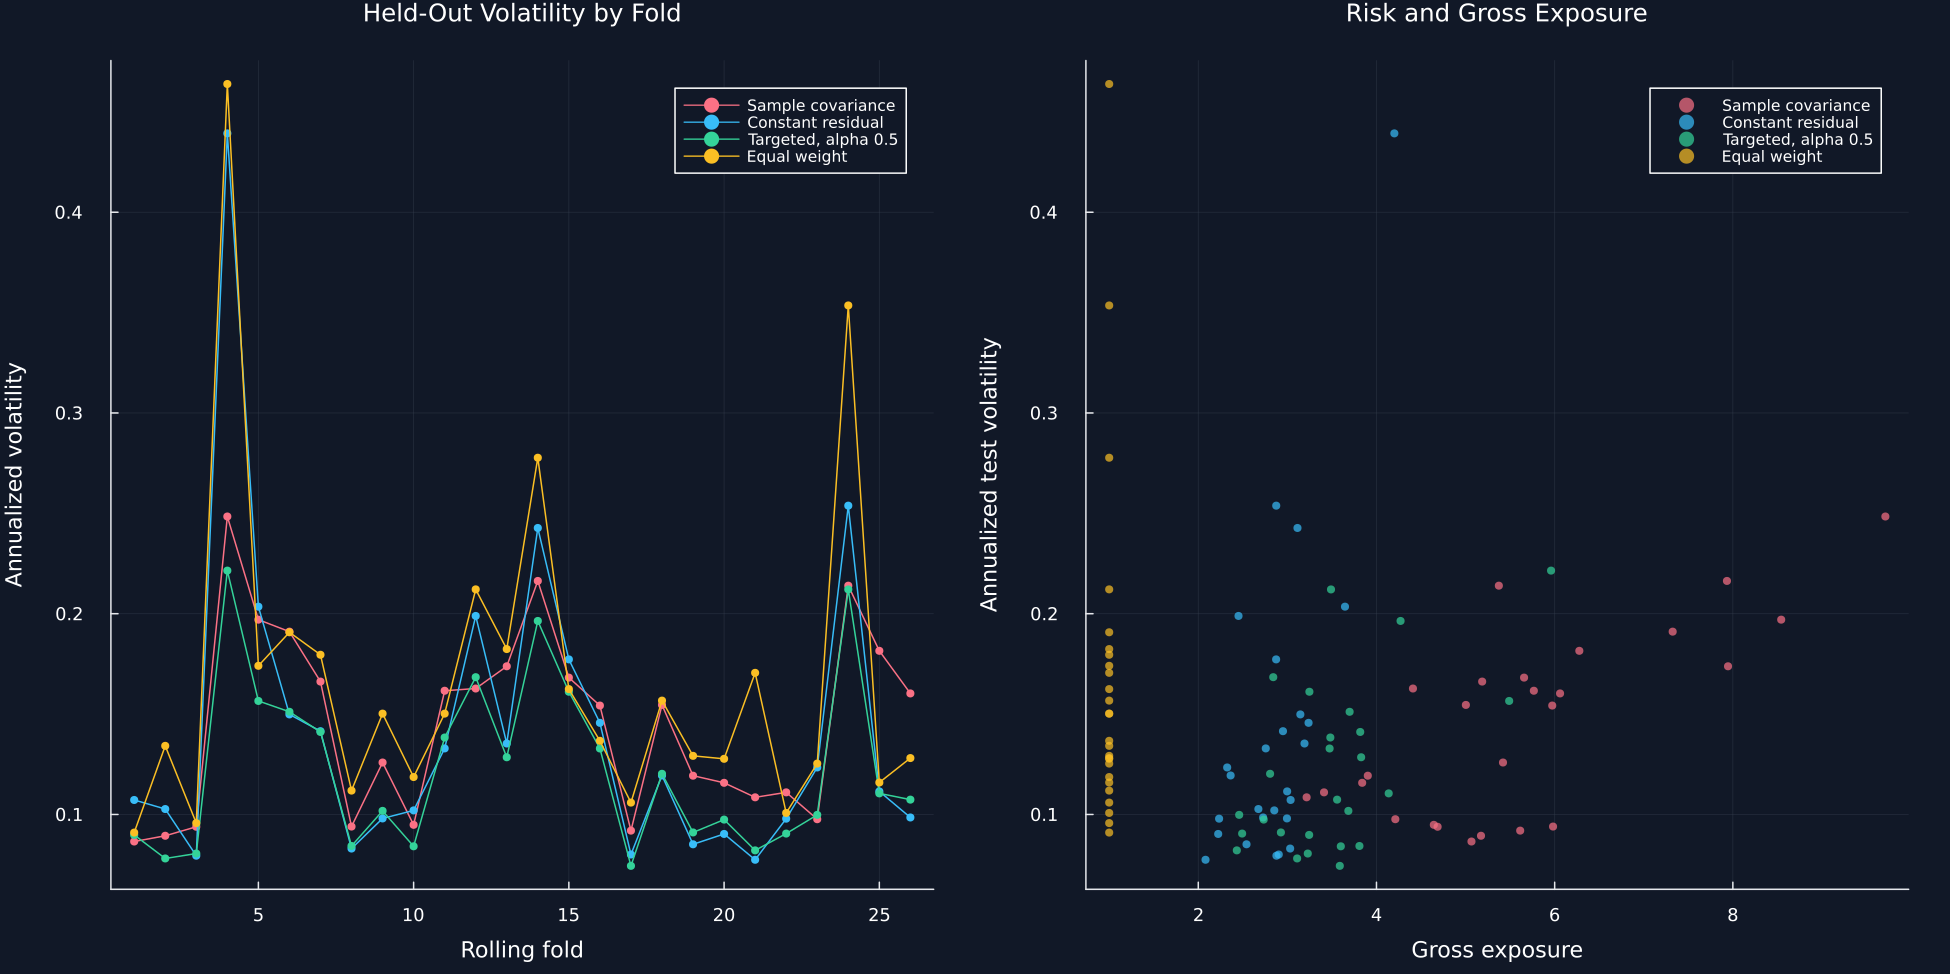

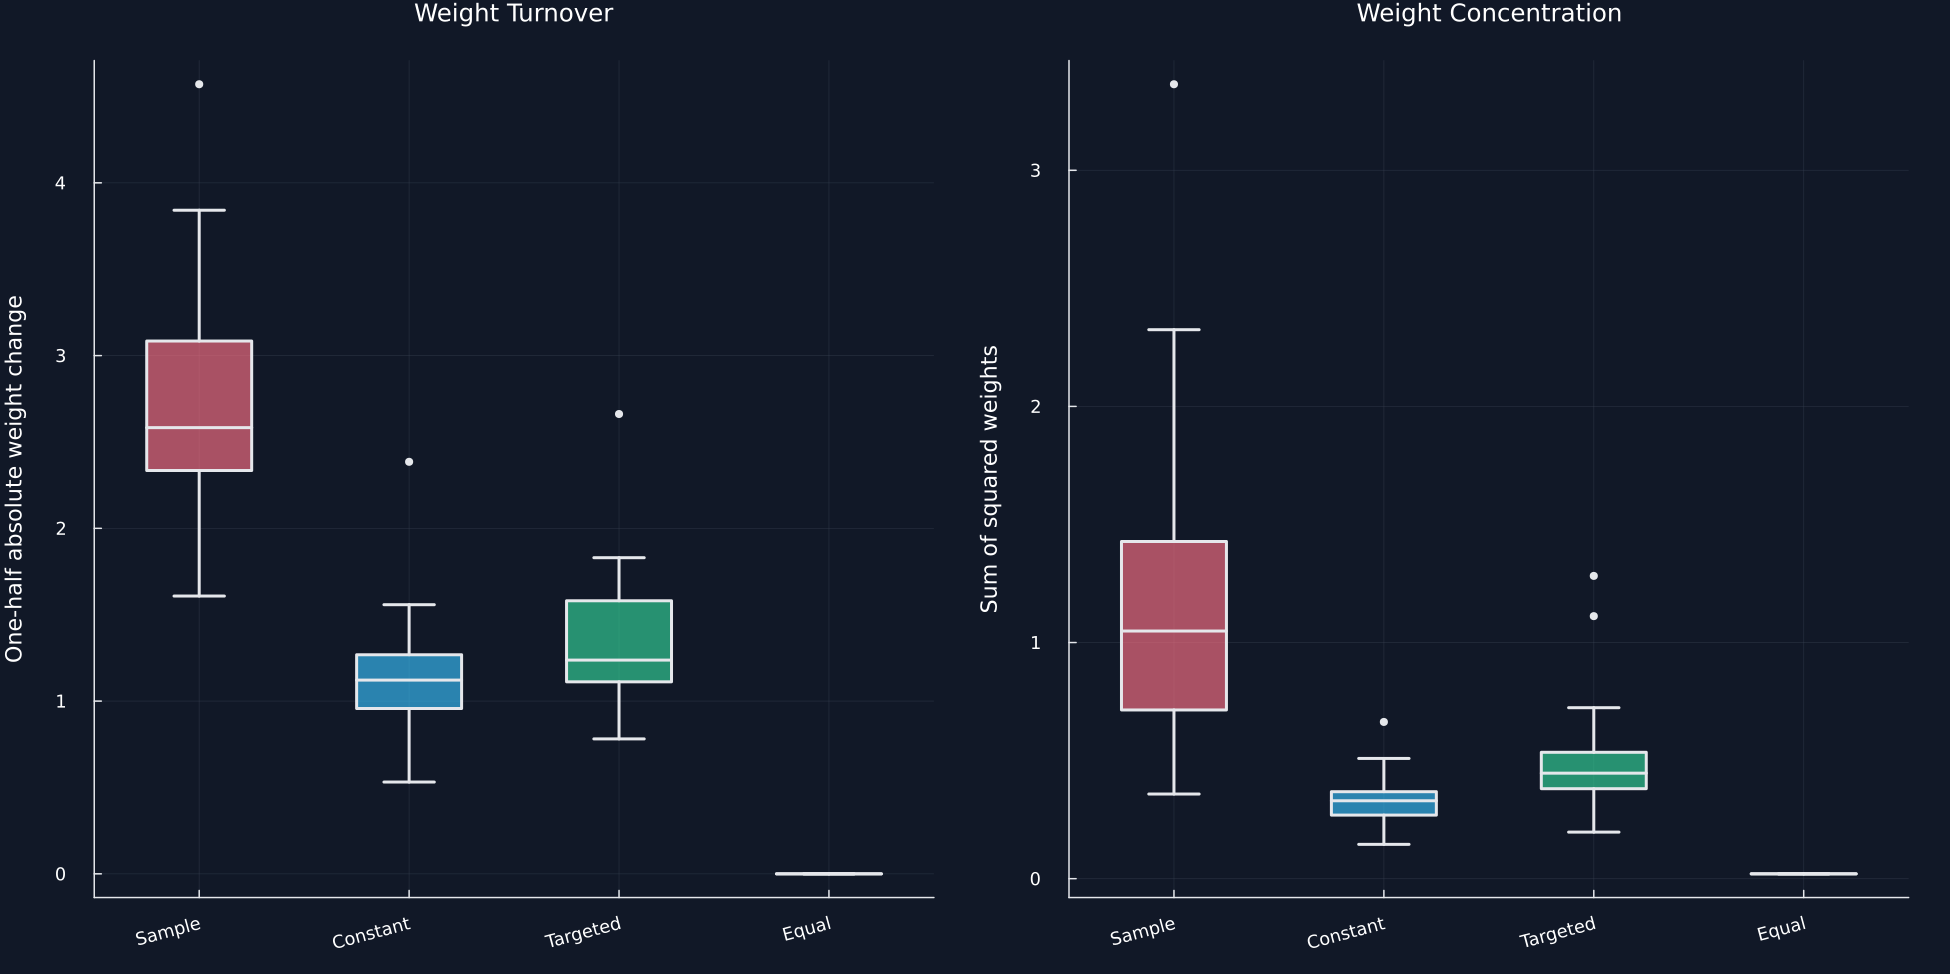

In [5]:
method_colors = [palette.rose,palette.cyan,palette.green,palette.amber]
p1 = plot(;title="Held-Out Volatility by Fold",xlabel="Rolling fold",ylabel="Annualized volatility",legend=:topright,legendfontsize=7)
p2 = plot(;title="Risk and Gross Exposure",xlabel="Gross exposure",ylabel="Annualized test volatility",legend=:topright,legendfontsize=7)
for (method,color) in zip(methods,method_colors)
    group = rolling_results[rolling_results.Method.==method,:]
    plot!(p1,group.Fold,group[!,"Annualized test volatility"];marker=:circle,markersize=3,markerstrokewidth=0,linewidth=1,color,label=method)
    scatter!(p2,group[!,"Gross exposure"],group[!,"Annualized test volatility"];markersize=3,markerstrokewidth=0,alpha=.7,color,label=method)
end
save_figure(plot(p1,p2;layout=(1,2),size=(1300,650)),paths,"rolling_portfolio_risk")
turnover_values = [filter(isfinite,rolling_results[rolling_results.Method.==method,"Turnover"]) for method in methods]
concentration_values = [rolling_results[rolling_results.Method.==method,"Weight concentration"] for method in methods]
p1 = plot(;title="Weight Turnover",ylabel="One-half absolute weight change",xticks=(1:4,["Sample","Constant","Targeted","Equal"]),xrotation=15,xlims=(.5,4.5),legend=false)
p2 = plot(;title="Weight Concentration",ylabel="Sum of squared weights",xticks=(1:4,["Sample","Constant","Targeted","Equal"]),xrotation=15,xlims=(.5,4.5),legend=false)
box_summary!(p1,turnover_values,method_colors)
box_summary!(p2,concentration_values,method_colors)
add_fliers!(p1,turnover_values)
add_fliers!(p2,concentration_values)
save_figure(plot(p1,p2;layout=(1,2),size=(1300,650)),paths,"rolling_weight_stability")


## Tests

In [6]:
@assert size(base_window)==(125,49)
@assert cond(base_correlation)>1
@assert all(inverse_sensitivity[!,"Relative covariance change"].>0)
@assert all(inverse_sensitivity[!,"Relative inverse change"].>0)
@assert all(diff(inverse_sensitivity[!,"Relative covariance change"]).>0)
@assert fold_number==26
@assert nrow(rolling_results)==104
@assert all(count(==(method),rolling_results.Method)==26 for method in methods)
@assert rolling_results[!,"Weight sum"]≈ones(104)
@assert all(rolling_results[!,"Annualized test volatility"].>0)
@assert all(rolling_results[!,"Gross exposure"].>=1-1e-12)
@assert all(1 .<=rolling_results[!,"Signal directions"].<=49)
@assert size(rolling_portfolio_summary)==(4,5)
@assert size(rolling_weight_summary)==(4,5)
@assert size(rolling_pairwise_summary)==(4,4)
@assert all(rolling_pairwise_summary[!,"Total folds"].==26)
@assert nrow(weight_recovery_runs)==300
@assert maximum(one_step_differences)<1e-12
@assert weight_recovery_summary[2,"Mean weight root mean squared error"]<weight_recovery_summary[1,"Mean weight root mean squared error"]
@assert weight_recovery_summary[2,"Mean weight root mean squared error"]≈weight_recovery_summary[3,"Mean weight root mean squared error"]
@assert isfile(joinpath(paths.figures,"rolling_portfolio_risk.pdf"))
@assert isfile(joinpath(paths.figures,"rolling_weight_stability.pdf"))
@assert isfile(joinpath(paths.figures,"known_truth_weight_recovery.pdf"))
@assert isfile(joinpath(paths.tables,"inverse_sensitivity.tex"))
@assert isfile(joinpath(paths.tables,"weight_recovery_summary.tex"))
@assert isfile(joinpath(paths.tables,"rolling_sample_summary.tex"))
@assert isfile(joinpath(paths.tables,"rolling_portfolio_summary.tex"))
@assert isfile(joinpath(paths.tables,"rolling_weight_summary.tex"))
@assert isfile(joinpath(paths.tables,"rolling_pairwise_summary.tex"))
